In [ ]:
# !pip install tensorflow
# !pip install contractions
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 37.6 MB/s  0:00:00


In [ ]:

import numpy as np
import pandas as pd
import contractions
import gensim.downloader as api

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk import pos_tag

from wordcloud import WordCloud, STOPWORDS

import spacy
import math
import re
import string
import unicodedata
import warnings

from gensim.models import Word2Vec
from joblib import Parallel, delayed
from textblob import TextBlob
from scipy.sparse import lil_matrix

import tensorflow
import keras

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.regularizers import l2
from tensorflow.keras.initializers import GlorotUniform
from tensorflow.keras.optimizers import Adam

from keras import layers
from keras.models import Sequential

from keras.layers import (
    SimpleRNN, LSTM, GRU, Embedding, Dense,
    SpatialDropout1D, Dropout, BatchNormalization,
    Bidirectional, Attention
)

warnings.filterwarnings('ignore')


Dataset loaded successfully!
Dataset shape: (3980, 2)
Columns: ['review', 'sentiment']
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
dataset shape:  (3980, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3980 entries, 0 to 3979
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     3980 non-null   object
 1   sentiment  3980 non-null   object
dtypes: object(2)
memory usage: 62.3+ KB
Duplicates in Dataset:  2


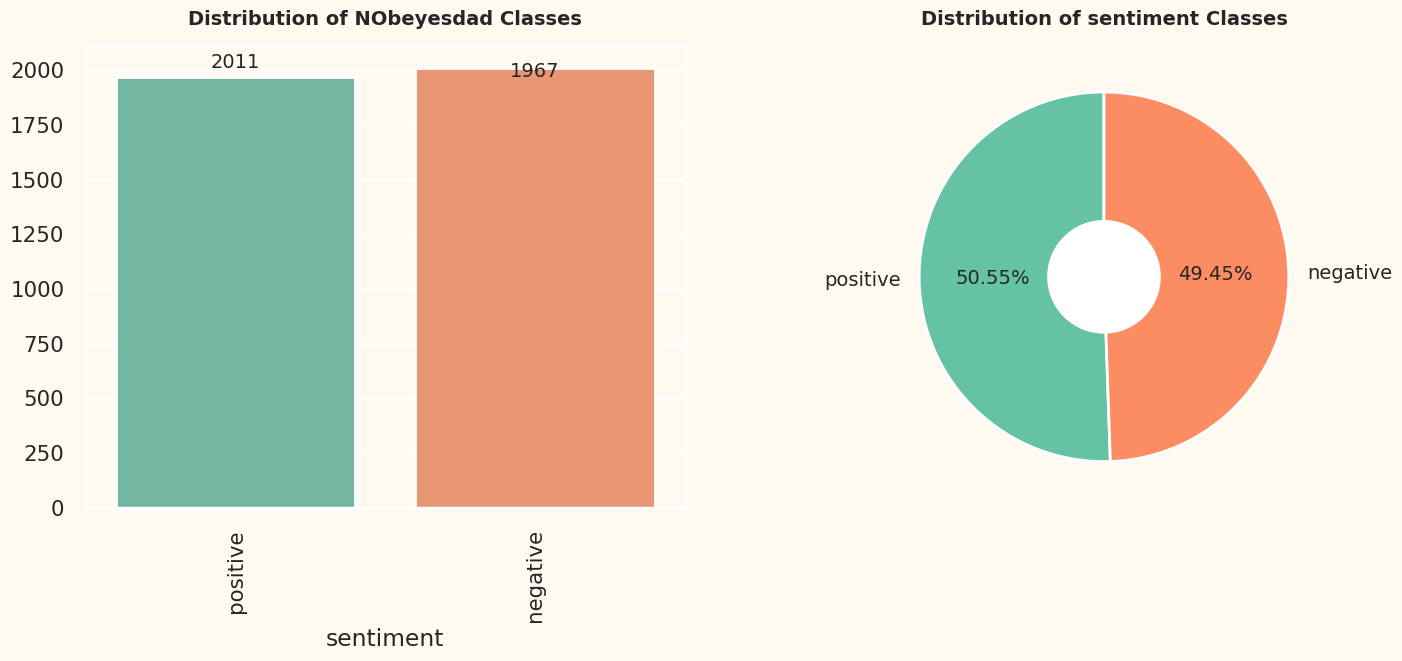

In [ ]:
try:
    df = pd.read_csv(
        '/content/IMDB.csv',
        encoding='utf-8',
        engine='python',
        on_bad_lines='warn'
    )

    df.columns = df.columns.str.strip().str.lower()

    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head())

except FileNotFoundError:
    print("Error: Please upload 'IMDB Dataset.csv' to /content/.")

sns.set(style="white", font_scale=1.5)
sns.set(rc={
    "axes.facecolor": "#FFFAF0",
    "figure.facecolor": "#FFFAF0"
})
sns.set_context("poster", font_scale=0.7)

print('dataset shape: ', df.shape)

df.info()

print("Duplicates in Dataset: ", df.duplicated().sum())

df.drop_duplicates(inplace=True)

missing_data = df.isnull().sum().to_frame().rename(
    columns={0: "Total No. of Missing Values"}
)

missing_data["% of Missing Values"] = round(
    (missing_data["Total No. of Missing Values"] / len(df)) * 100, 2
)

missing_data

round(df.describe(include="O").T, 2)


classes = ['positive', 'negative']

plt.figure(figsize=(17, 6))

plt.subplot(1, 2, 1)

sentiment_counts = df["sentiment"].value_counts()

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values,
    palette='Set2',
    order=classes
)

plt.title(
    "Distribution of NObeyesdad Classes",
    fontweight="black",
    size=14,
    pad=15
)

for i, v in enumerate(sentiment_counts.values):
    plt.text(i, v, v, ha="center", fontsize=14)

plt.xticks(rotation=90)

plt.subplot(1, 2, 2)

colors = sns.color_palette('Set2', len(classes))

plt.pie(
    sentiment_counts,
    labels=classes,
    autopct="%.2f%%",
    textprops={"size": 14},
    colors=colors,
    startangle=90
)

center_circle = plt.Circle((0, 0), 0.3, fc='white')

fig = plt.gcf()
fig.gca().add_artist(center_circle)

plt.title(
    "Distribution of sentiment Classes",
    fontweight="black",
    size=14,
    pad=15
)

plt.show()


Dataset shape: (49582, 2)
Missing values:
 review       0
sentiment    0
dtype: int64


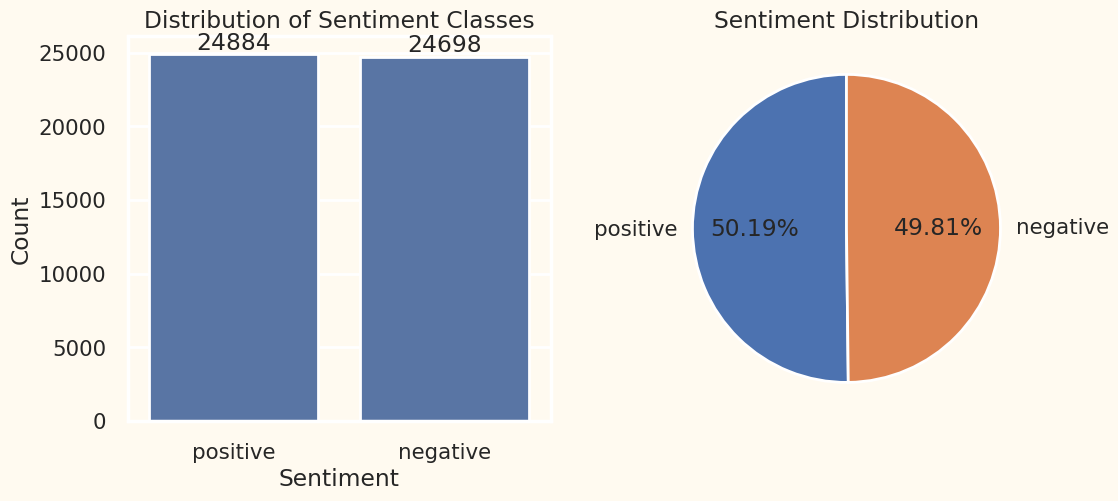

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
496/496 ━━━━━━━━━━━━━━━━━━━━ 267s 529ms/step - accuracy: 0.7930 - loss: 0.4461 - val_accuracy: 0.8600 - val_loss: 0.3385
Epoch 2/3
496/496 ━━━━━━━━━━━━━━━━━━━━ 324s 534ms/step - accuracy: 0.8619 - loss: 0.3341 - val_accuracy: 0.8550 - val_loss: 0.3483
Epoch 3/3
496/496 ━━━━━━━━━━━━━━━━━━━━ 270s 545ms/step - accuracy: 0.8942 - loss: 0.2683 - val_accuracy: 0.8605 - val_loss: 0.3401
310/310 ━━━━━━━━━━━━━━━━━━━━ 24s 77ms/step - accuracy: 0.8676 - loss: 0.3191
Test Accuracy: 86.76 %


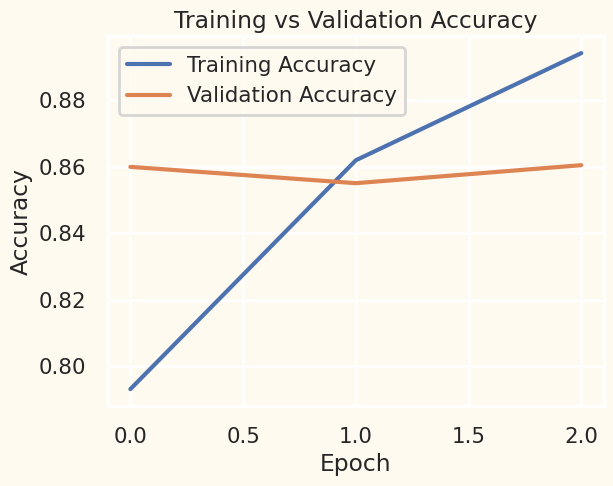

In [ ]:
# ---------- Load dataset ----------
df = pd.read_csv('/content/IMDB.csv')
df = df.drop_duplicates().reset_index(drop=True)
print("Dataset shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
# ---------- Sentiment distribution (bar chart + pie chart) ----------
counts = df['sentiment'].value_counts()[['positive', 'negative']]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x='sentiment', data=df, order=['positive', 'negative'], ax=ax[0])
for i, v in enumerate(counts):
 ax[0].text(i, v, str(v), ha='center', va='bottom')
ax[0].set_title('Distribution of Sentiment Classes')
ax[0].set_xlabel('Sentiment')
ax[0].set_ylabel('Count')
ax[1].pie(counts, labels=counts.index, autopct='%1.2f%%', startangle=90)
ax[1].set_title('Sentiment Distribution')
plt.show()
# ---------- Pre-processing ----------
def clean(text):
 text = re.sub(r'<.*?>', ' ', text) # remove HTML tags such as <br />
 return text.lower()
df['review'] = df['review'].apply(clean)
df['label'] = (df['sentiment'] == 'positive').astype(int)
max_features = 10000 # vocabulary size
max_len = 200 # maximum length of each review
x_train, x_test, y_train, y_test = train_test_split(
 df['review'], df['label'], test_size=0.2, random_state=42, stratify=df['label'])
tokenizer = Tokenizer(num_words=max_features)
tokenizer.fit_on_texts(x_train)
x_train = pad_sequences(tokenizer.texts_to_sequences(x_train), maxlen=max_len)
x_test = pad_sequences(tokenizer.texts_to_sequences(x_test), maxlen=max_len)
# ---------- Build model ----------
model = Sequential([
 Embedding(input_dim=max_features, output_dim=128, input_length=max_len),
 SpatialDropout1D(0.2),
 LSTM(100, dropout=0.2, recurrent_dropout=0.2),
 Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()
# ---------- Train model ----------
history = model.fit(x_train, y_train, epochs=3,
 batch_size=64, validation_split=0.2)
# ---------- Evaluate model ----------
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", round(accuracy * 100, 2), "%")
# ---------- Plot accuracy ----------
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.show()